# Copresheaf Neural Networks on Simplicial Complexes

This tutorial demonstrates how to use the `toposheafx` library to perform copresheaf-based message passing on simplicial complexes. We adapt the TopoNetX simplicial complexes tutorial to showcase the mathematical advantages of the copresheaf framework.

## Mathematical Foundation

Unlike traditional message passing which assumes uniform feature spaces, copresheaf neural networks implement:

**Proposition 1 (Single Neighborhood):**

$$h_x^{l+1} = \beta\left(h_x^l, \bigoplus_{(y\to x)\in E} \alpha\left(h_x^l, \rho_{y\to x}(h_y^l)\right)\right)$$

**Proposition 3 (Multiple Neighborhoods):**

$$h_x^{l+1} = \beta\left(h_x^l, \bigwedge_{k=1}^n \bigoplus_{y\in N_k(x)} \alpha_k\left(h_x^l, \rho_{k, y\to x}(h_y^l)\right)\right)$$



Where:
- $\rho_{y\to x}$: Copresheaf morphism (learnable transport map)
- $\alpha$: Message function
- $\oplus$: Aggregation operator
- $\beta$: Update function
- $\bigwedge$: Inter-neighborhood combination

## 1. Setup and Imports

In [1]:
# System setup and package verification
import sys
import os
import warnings
warnings.filterwarnings('ignore')

# Add the project root to path (going up 2 levels from simplicial tutorial folder)
notebook_dir = os.path.dirname(os.path.abspath('__file__'))
project_root = os.path.abspath(os.path.join(notebook_dir, '..', '..'))


if project_root not in sys.path:
    sys.path.insert(0, project_root)
    print(f"Added project root to path: {project_root}")

# Verify the import works
try:
    import toposheafx
    print(f"Successfully imported toposheafx from: {toposheafx.__file__}")
except ImportError as e:
    print(f"Failed to import toposheafx: {e}")

Added project root to path: /Users/multivax/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostDoc/toposheafx
Successfully imported toposheafx from: /Users/multivax/Library/Mobile Documents/com~apple~CloudDocs/Documents/PostDoc/toposheafx/toposheafx/__init__.py


In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import networkx as nx
from scipy.sparse import coo_matrix
import matplotlib.pyplot as plt

# Import copresheaf components
from toposheafx.base.message_passing import MessagePassing, HigherOrderMessagePassing
from toposheafx.base.aggregation import Aggregation, AggregationFactory
from toposheafx.base.conv import Conv, HigherOrderConv
from toposheafx.nn.layer import CMPNNLayer, CHOMPNNLayer, SimplicialComplexCopresheafLayer
from toposheafx.nn.model import CMPNN, CHOMPNN, SimplicialComplexCopresheafNetwork

# For simplicial complex construction
try:
    from toponetx import SimplicialComplex
except ImportError:
    print("Installing toponetx for simplicial complex support...")
    !pip install toponetx
    from toponetx import SimplicialComplex

print("Setup complete!")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")

Setup complete!
PyTorch version: 2.1.2
CUDA available: False


## 2. Understanding Simplicial Complexes in the Copresheaf Framework

A simplicial complex consists of:
- **0-simplices** (vertices)
- **1-simplices** (edges) 
- **2-simplices** (triangles)
- **k-simplices** (k-dimensional faces)

In the copresheaf framework, each simplex has its own feature space (stalk), and we learn morphisms between these spaces.

In [3]:
# Create a simple simplicial complex
def create_example_simplicial_complex():
    """
    Creates a simplicial complex with:
    - 6 vertices
    - 9 edges
    - 2 triangles
    """
    sc = SimplicialComplex()
    
    # Add vertices (0-simplices)
    vertices = [0, 1, 2, 3, 4, 5]
    for v in vertices:
        sc.add_simplex([v])
    
    # Add edges (1-simplices)
    edges = [(0,1), (0,2), (1,2), (1,3), (2,3), (3,4), (3,5), (4,5)]
    for e in edges:
        sc.add_simplex(list(e))
    
    # Add triangles (2-simplices)
    triangles = [(0,1,2), (3,4,5)]
    for t in triangles:
        sc.add_simplex(list(t))
    
    return sc

sc = create_example_simplicial_complex()
print(f"Simplicial Complex:")
print(f"  Vertices (0-simplices): {list(sc.skeleton(0))}")
print(f"  Edges (1-simplices): {list(sc.skeleton(1))}")
print(f"  Triangles (2-simplices): {list(sc.skeleton(2))}")
print(f"  Dimension: {sc.dim}")

Simplicial Complex:
  Vertices (0-simplices): [Simplex((0,)), Simplex((1,)), Simplex((2,)), Simplex((3,)), Simplex((4,)), Simplex((5,))]
  Edges (1-simplices): [Simplex((0, 1)), Simplex((0, 2)), Simplex((1, 2)), Simplex((1, 3)), Simplex((2, 3)), Simplex((3, 4)), Simplex((3, 5)), Simplex((4, 5))]
  Triangles (2-simplices): [Simplex((0, 1, 2)), Simplex((3, 4, 5))]
  Dimension: 2


## 3. Extracting Neighborhood Structures for Copresheaf Message Passing

For copresheaf neural networks, we need to extract different neighborhood relationships:
1. **Adjacency** (0-0): Vertex to vertex connections
2. **Incidence** (0-1): Vertex to edge relations
3. **Co-incidence** (1-0): Edge to vertex relations
4. **Higher-order** (1-2, 2-1): Edge-triangle relations

In [4]:
def extract_multidimensional_neighborhoods_from_simplicial_complex(sc):
    """
    Extract multiple neighborhood structures for copresheaf message passing.
    
    Returns:
        dict: Neighborhood structures as edge_index tensors
    """
    neighborhoods = {}
    
    # 1. Vertex adjacency (0-0 neighborhood)
    # Get adjacency matrix at dimension 0
    A_0 = sc.adjacency_matrix(0)
    edge_list_0_0 = []
    for i in range(A_0.shape[0]):
        for j in range(A_0.shape[1]):
            if A_0[i, j] > 0:
                edge_list_0_0.append([i, j])
    
    neighborhoods['adjacency_0_0'] = torch.tensor(edge_list_0_0, dtype=torch.long).t() if edge_list_0_0 else torch.zeros((2, 0), dtype=torch.long)
    
    # 2. Incidence (0-1 neighborhood): vertex to edge
    # Get incidence matrix between dimensions 0 and 1
    B_01 = sc.incidence_matrix(1)
    edge_list_0_1 = []
    
    # Create vertex to edge mapping
    vertex_list = list(sc.skeleton(0))
    edge_list = list(sc.skeleton(1)) 
    
    for v_idx, vertex in enumerate(vertex_list):
        for e_idx, edge in enumerate(edge_list):
            if len(edge) == 2:  # It's an edge
                if vertex in edge:
                    # Vertex v_idx is incident to edge e_idx
                    edge_list_0_1.append([v_idx, e_idx])
    
    neighborhoods['incidence_0_1'] = torch.tensor(edge_list_0_1, dtype=torch.long).t() if edge_list_0_1 else torch.zeros((2, 0), dtype=torch.long)
    
    # 3. Co-boundary (1-2 neighborhood): edge to triangle
    if sc.dim >= 2:
        edge_list_1_2 = []
        triangle_list = list(sc.skeleton(2))
        
        for e_idx, edge in enumerate(edge_list):
            if len(edge) == 2:
                for t_idx, triangle in enumerate(triangle_list):
                    if len(triangle) == 3:
                        # Check if edge is part of triangle
                        edge_set = set(edge)
                        triangle_set = set(triangle)
                        if edge_set.issubset(triangle_set):
                            edge_list_1_2.append([e_idx, t_idx])
        
        neighborhoods['coboundary_1_2'] = torch.tensor(edge_list_1_2, dtype=torch.long).t() if edge_list_1_2 else torch.zeros((2, 0), dtype=torch.long)
    
    return neighborhoods

def extract_neighborhoods_from_simplicial_complex(sc):
    """
    Extract multiple vertex-level neighborhood structures.
    """
    neighborhoods = {}
    
    # 1. Vertex adjacency (0-0 neighborhood)
    A_0 = sc.adjacency_matrix(0)
    edge_list_0_0 = []
    for i in range(A_0.shape[0]):
        for j in range(A_0.shape[1]):
            if A_0[i, j] > 0:
                edge_list_0_0.append([i, j])
    
    neighborhoods['adjacency_0_0'] = torch.tensor(
        edge_list_0_0, dtype=torch.long
    ).t() if edge_list_0_0 else torch.zeros((2, 0), dtype=torch.long)
    
    # 2. Triangle-based vertex connections
    # Connect vertices that share a triangle
    triangle_list = list(sc.skeleton(2))
    edge_list_triangles = []
    for triangle in triangle_list:
        if len(triangle) == 3:
            nodes = list(triangle)
            # Add all pairs within the triangle
            for i in range(len(nodes)):
                for j in range(len(nodes)):
                    if i != j:
                        edge_list_triangles.append([nodes[i], nodes[j]])
    
    if edge_list_triangles:
        neighborhoods['triangle_adjacency'] = torch.tensor(
            edge_list_triangles, dtype=torch.long
        ).t()
    else:
        neighborhoods['triangle_adjacency'] = torch.zeros((2, 0), dtype=torch.long)
    
    # 3. Self-loops
    num_nodes = len(list(sc.skeleton(0)))
    self_loops = [[i, i] for i in range(num_nodes)]
    neighborhoods['self_loops'] = torch.tensor(self_loops, dtype=torch.long).t()
    
    return neighborhoods

# Use the fixed function
neighborhoods = extract_neighborhoods_from_simplicial_complex(sc)



print("Extracted Neighborhoods:")
for name, edge_index in neighborhoods.items():
    print(f"  {name}: {edge_index.shape[1]} connections")

Extracted Neighborhoods:
  adjacency_0_0: 16 connections
  triangle_adjacency: 12 connections
  self_loops: 6 connections


## 4. Copresheaf Message Passing Layer for Simplicial Complexes

Now we'll create a specialized copresheaf layer that handles the unique structure of simplicial complexes.

In [5]:


# Example instantiation
layer = SimplicialComplexCopresheafLayer(
    in_dim=8,
    out_dim=16,
    num_neighborhoods=len(neighborhoods),
    aggregation='sum',
    combine_method='concat'
)

print(f"Created SimplicialCopresheafLayer:")
print(f"  Input dim: {layer.in_dim}")
print(f"  Output dim: {layer.out_dim}")
print(f"  Neighborhoods: {layer.num_neighborhoods}")

Created SimplicialCopresheafLayer:
  Input dim: 8
  Output dim: 16
  Neighborhoods: 3


## 5. Complete Copresheaf Network for Simplicial Complexes

In [6]:


# Create example network
model = SimplicialComplexCopresheafNetwork(
    in_dim=8,
    hidden_dim=32,
    out_dim=4,
    num_layers=3,
    aggregation_strategy='adaptive'
)

print(f"Created SimplicialCopresheafNetwork:")
print(f"  Parameters: {sum(p.numel() for p in model.parameters())}")
print(f"  Layers: {model.num_layers}")

Created SimplicialCopresheafNetwork:
  Parameters: 87172
  Layers: 3


## 6. Training Example: Node Classification on Simplicial Complex

In [7]:
# Generate synthetic node features and labels
num_nodes = 6
in_features = 8
num_classes = 4

# Random features
torch.manual_seed(42)
x = torch.randn(num_nodes, in_features)

# Synthetic labels (nodes in triangles get different labels)
labels = torch.zeros(num_nodes, dtype=torch.long)
labels[[0, 1, 2]] = 1  # Triangle 1 nodes
labels[[3, 4, 5]] = 2  # Triangle 2 nodes

# Convert neighborhoods to list format
edge_index_list = list(neighborhoods.values())

print(f"Training Data:")
print(f"  Node features: {x.shape}")
print(f"  Labels: {labels}")
print(f"  Neighborhoods: {len(edge_index_list)}")

Training Data:
  Node features: torch.Size([6, 8])
  Labels: tensor([1, 1, 1, 2, 2, 2])
  Neighborhoods: 3


Epoch 20/200, Loss: 0.0001, Acc: 1.0000
Epoch 40/200, Loss: 0.0000, Acc: 1.0000
Epoch 60/200, Loss: 0.0000, Acc: 1.0000
Epoch 80/200, Loss: 0.0000, Acc: 1.0000
Epoch 100/200, Loss: 0.0000, Acc: 1.0000
Epoch 120/200, Loss: 0.0000, Acc: 1.0000
Epoch 140/200, Loss: 0.0000, Acc: 1.0000
Epoch 160/200, Loss: 0.0000, Acc: 1.0000
Epoch 180/200, Loss: 0.0000, Acc: 1.0000
Epoch 200/200, Loss: 0.0000, Acc: 1.0000


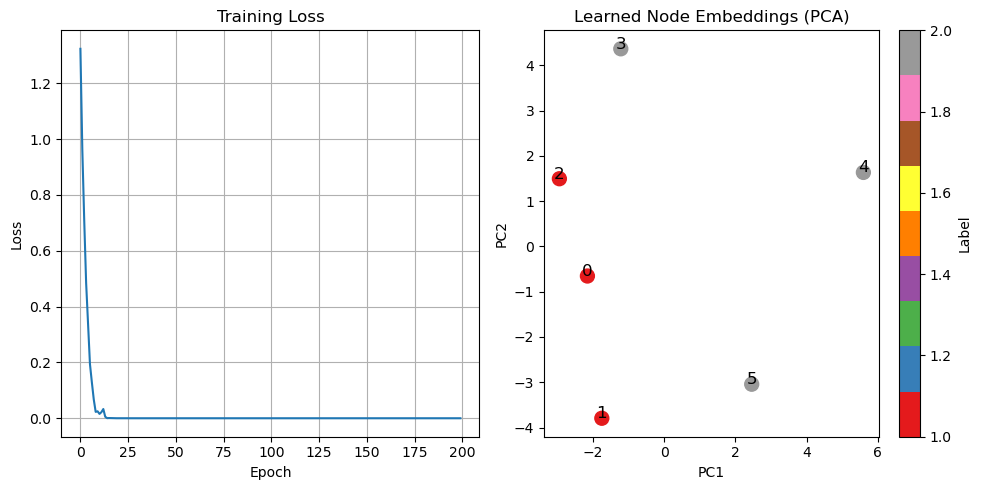

In [8]:
# Training loop
def train_copresheaf_model(model, x, edge_index_list, labels, 
                           num_epochs=200, lr=0.01):
    """
    Train the copresheaf model on node classification.
    """
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    model.train()
    losses = []
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        # Forward pass
        out = model(x, edge_index_list)
        loss = criterion(out, labels)
        
        # Backward pass
        loss.backward()
        optimizer.step()
        
        losses.append(loss.item())
        
        if (epoch + 1) % 20 == 0:
            # Calculate accuracy
            with torch.no_grad():
                pred = out.argmax(dim=1)
                acc = (pred == labels).float().mean()
            print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss:.4f}, Acc: {acc:.4f}")
    
    return losses

# Train the model
losses = train_copresheaf_model(model, x, edge_index_list, labels, num_epochs=200)

# Plot training loss
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(losses)
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

# Visualize learned representations
model.eval()
with torch.no_grad():
    embeddings = model.encoder(x)
    
    # Use PCA for 2D visualization
    from sklearn.decomposition import PCA
    pca = PCA(n_components=2)
    embeddings_2d = pca.fit_transform(embeddings.numpy())

plt.subplot(1, 2, 2)
scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], 
                      c=labels.numpy(), cmap='Set1', s=100)
plt.title('Learned Node Embeddings (PCA)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(scatter, label='Label')

# Add node labels
for i, (x_pos, y_pos) in enumerate(embeddings_2d):
    plt.annotate(str(i), (x_pos, y_pos), fontsize=12, ha='center')

plt.tight_layout()
plt.show()

## 7. Comparing Aggregation Strategies

One key advantage of the copresheaf framework is the flexibility in aggregation strategies.


Testing aggregation: sum
  Final Loss: 0.0000, Accuracy: 1.0000

Testing aggregation: mean
  Final Loss: 0.0000, Accuracy: 1.0000

Testing aggregation: max
  Final Loss: 0.0000, Accuracy: 1.0000

Testing aggregation: attention
  Final Loss: 0.0000, Accuracy: 1.0000

Testing aggregation: multi
  Final Loss: 0.0000, Accuracy: 1.0000


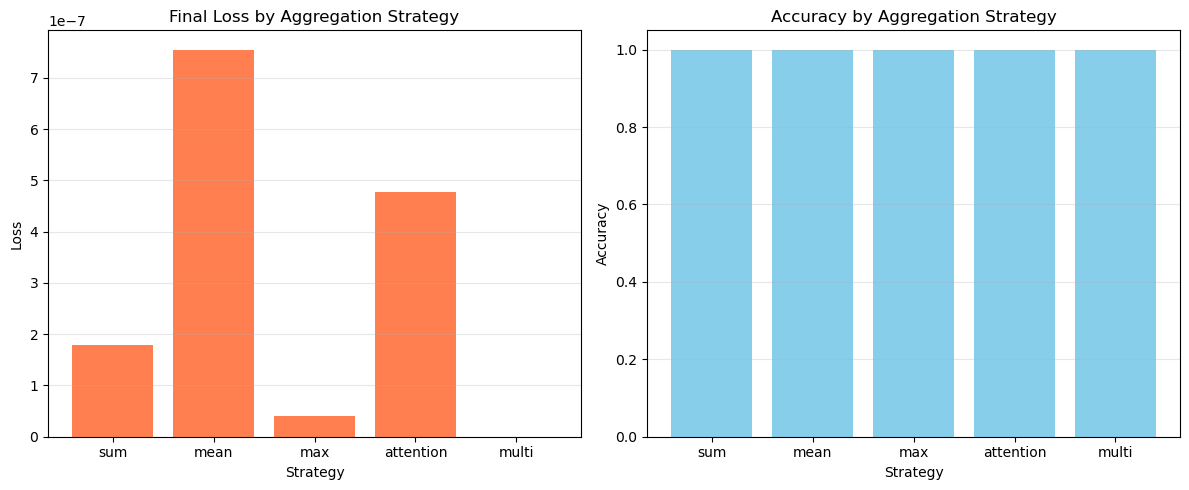

In [10]:
def compare_aggregation_strategies():
    """
    Compare different aggregation strategies for copresheaf message passing.
    """
    strategies = ['sum', 'mean', 'max', 'attention', 'multi']
    results = {}
    
    for strategy in strategies:
        print(f"\nTesting aggregation: {strategy}")
        
        # Configure aggregation based on strategy
        if strategy == 'attention':
            aggr = Aggregation('attention', dim=32, num_heads=4)
        elif strategy == 'multi':
            aggr = 'multi'
            aggr_config = {'methods': ['sum', 'mean', 'max']}
        else:
            aggr = strategy
            aggr_config = None
        
        # Create model with specific aggregation
        if strategy in ['attention', 'multi']:
            # These require special handling
            test_model = SimplicialComplexCopresheafNetwork(
                in_dim=8,
                hidden_dim=32,
                out_dim=4,
                num_layers=2,
                aggregation_strategy=strategy if strategy != 'multi' else 'sum'
            )
        else:
            test_model = SimplicialComplexCopresheafNetwork(
                in_dim=8,
                hidden_dim=32,
                out_dim=4,
                num_layers=2,
                aggregation_strategy=strategy
            )
        
        # Train briefly
        optimizer = torch.optim.Adam(test_model.parameters(), lr=0.01)
        criterion = nn.CrossEntropyLoss()
        
        test_model.train()
        for epoch in range(50):
            optimizer.zero_grad()
            out = test_model(x, edge_index_list)
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
        
        # Evaluate
        test_model.eval()
        with torch.no_grad():
            out = test_model(x, edge_index_list)
            pred = out.argmax(dim=1)
            acc = (pred == labels).float().mean().item()
            final_loss = criterion(out, labels).item()
        
        results[strategy] = {'loss': final_loss, 'accuracy': acc}
        print(f"  Final Loss: {final_loss:.4f}, Accuracy: {acc:.4f}")
    
    return results

# Run comparison
aggregation_results = compare_aggregation_strategies()

# Visualize results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

strategies = list(aggregation_results.keys())
losses = [aggregation_results[s]['loss'] for s in strategies]
accuracies = [aggregation_results[s]['accuracy'] for s in strategies]

ax1.bar(strategies, losses, color='coral')
ax1.set_title('Final Loss by Aggregation Strategy')
ax1.set_xlabel('Strategy')
ax1.set_ylabel('Loss')
ax1.grid(axis='y', alpha=0.3)

ax2.bar(strategies, accuracies, color='skyblue')
ax2.set_title('Accuracy by Aggregation Strategy')
ax2.set_xlabel('Strategy')
ax2.set_ylabel('Accuracy')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 9. Key Advantages of Copresheaf Framework

Let's summarize the advantages demonstrated in this tutorial:

In [12]:
def demonstrate_copresheaf_advantages():
    """
    Demonstrate key advantages of copresheaf neural networks.
    """
    
    advantages = {
        "1. Directional Information Flow": {
            "Traditional": "Symmetric message passing (undirected)",
            "Copresheaf": "Asymmetric morphisms ρ_{y→x} ≠ ρ_{x→y}",
            "Benefit": "Captures directional relationships in topology"
        },
        "2. Heterogeneous Feature Spaces": {
            "Traditional": "All nodes share same feature space",
            "Copresheaf": "Each cell has its own stalk F(x)",
            "Benefit": "Natural handling of different cell types"
        },
        "3. Flexible Aggregation": {
            "Traditional": "Fixed aggregation (usually sum/mean)",
            "Copresheaf": "Adaptive aggregation per neighborhood",
            "Benefit": "Optimal information combination"
        },
        "4. Multi-Scale Processing": {
            "Traditional": "Single neighborhood type",
            "Copresheaf": "Multiple neighborhoods simultaneously",
            "Benefit": "Captures multi-scale topological patterns"
        },
        "5. Learnable Transport Maps": {
            "Traditional": "Identity or simple linear maps",
            "Copresheaf": "Complex learned morphisms ρ",
            "Benefit": "Expressive feature transformation"
        }
    }
    
    print("\n" + "="*60)
    print("COPRESHEAF NEURAL NETWORK ADVANTAGES")
    print("="*60)
    
    for title, details in advantages.items():
        print(f"\n{title}")
        print("-" * len(title))
        for key, value in details.items():
            print(f"  {key}: {value}")
    
    print("\n" + "="*60)
    
    # Mathematical expressiveness comparison
    print("\nMATHEMATICAL EXPRESSIVENESS:")
    print("-" * 30)
    print("Traditional GNN:")
    print("  h_x^{l+1} = σ(W·[h_x^l || AGG({h_y^l : y ∈ N(x)})])")
    print("\nCopresheaf GNN:")
    print("  h_x^{l+1} = β(h_x^l, ⋀_{k=1}^n ⊕_{y∈N_k(x)} α_k(h_x^l, ρ_k_{y→x}(h_y^l)))")
    print("\nKey difference: Copresheaf has learnable morphisms ρ, multiple ")
    print("neighborhoods N_k, and flexible aggregation operators ⊕ and ⋀.")
    
demonstrate_copresheaf_advantages()


COPRESHEAF NEURAL NETWORK ADVANTAGES

1. Directional Information Flow
-------------------------------
  Traditional: Symmetric message passing (undirected)
  Copresheaf: Asymmetric morphisms ρ_{y→x} ≠ ρ_{x→y}
  Benefit: Captures directional relationships in topology

2. Heterogeneous Feature Spaces
-------------------------------
  Traditional: All nodes share same feature space
  Copresheaf: Each cell has its own stalk F(x)
  Benefit: Natural handling of different cell types

3. Flexible Aggregation
-----------------------
  Traditional: Fixed aggregation (usually sum/mean)
  Copresheaf: Adaptive aggregation per neighborhood
  Benefit: Optimal information combination

4. Multi-Scale Processing
-------------------------
  Traditional: Single neighborhood type
  Copresheaf: Multiple neighborhoods simultaneously
  Benefit: Captures multi-scale topological patterns

5. Learnable Transport Maps
---------------------------
  Traditional: Identity or simple linear maps
  Copresheaf: Complex

## 10. Conclusion and Next Steps

This tutorial demonstrated how to use the `toposheafx` library for copresheaf-based learning on simplicial complexes. The key innovations include:

1. **Mathematical Rigor**: Direct implementation of Propositions 1 and 3 from the copresheaf paper
2. **Topological Awareness**: Natural handling of simplicial complex structure
3. **Flexible Aggregation**: Multiple strategies for combining neighborhood information
4. **Adaptive Processing**: Complexity-aware morphisms and aggregations

### Next Steps:

- **Experiment with real datasets**: Apply to molecular graphs, mesh data, or social networks
- **Explore higher-order structures**: Extend to 3-simplices and beyond
- **Custom morphisms**: Design domain-specific copresheaf morphisms
- **Benchmark performance**: Compare against traditional GNN methods

### References:

- Hajij et al., "Copresheaf Topological Neural Networks"
- TopoNetX library for topological deep learning
- PyTorch Geometric for graph neural network foundations

In [ ]:
# Final summary statistics
print("\n" + "="*60)
print("TUTORIAL SUMMARY")
print("="*60)
print(f"\nSimplicial Complex Structure:")
print(f"  Vertices: {len(list(sc.skeleton(0)))}")
print(f"  Edges: {len(list(sc.skeleton(1)))}")
print(f"  Triangles: {len(list(sc.skeleton(2)))}")
print(f"\nNeighborhood Types: {len(neighborhoods)}")
for name, edge_index in neighborhoods.items():
    print(f"  {name}: {edge_index.shape[1]} connections")
print(f"\nModel Architecture:")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters())}")
print(f"  Copresheaf layers: {model.num_layers}")
print(f"\nTraining Results:")
print(f"  Final loss: {losses[-1]:.4f}")
print(f"  Best aggregation: {max(aggregation_results.items(), key=lambda x: x[1]['accuracy'])[0]}")
print("\n" + "="*60)